# <center>PTA Gravitational Wave Searches - part 2</center>

### <center><span style="font-family:Comic Sans MS; color:blue">Prepared by Valentina Di Marco</span></center>

<div style = 'background-color:yellow'> Before running the tutorial make a directory using your name and save a copy of Plots.ipynb  in it </div>

In this second part of the tutorial, we’ll use pre-generated chains to visualize the estimated parameters from the injected signal in a single pulsar (J0437–4715), as well as the parameters associated with a common signal, such as that expected from a gravitational wave background.

We’ll also plot the optimal statistic (OS)

In [1]:
import numpy as np
import chainconsumer
from chainconsumer import ChainConsumer
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

In [2]:
# some nice estetics for matplotlib
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'

linestyles = "-"
linewidths = 1.0
shade = True
shade_gradient = 2.0
shade_alpha = 0.2
colors = mcolors.CSS4_COLORS['mediumblue']
sigmas = [1, 2]
tfs = 18 #tick
lfs = 27 #label

Load the chains and the par files

In [3]:
datadir = '/fred/oz005/users/pulsar_workshop/valentina2/PTA_tutorials/chains_noise/'
all_data = np.load(datadir + 'chain.npy')
pars = np.loadtxt(datadir + '/pars.txt', dtype=np.unicode_)

Here we plot the estimated parameters for the white noise. Injected values for pulsar J0437-4715: EFAC=1, ECORR=not injected, EQUAD=not injected

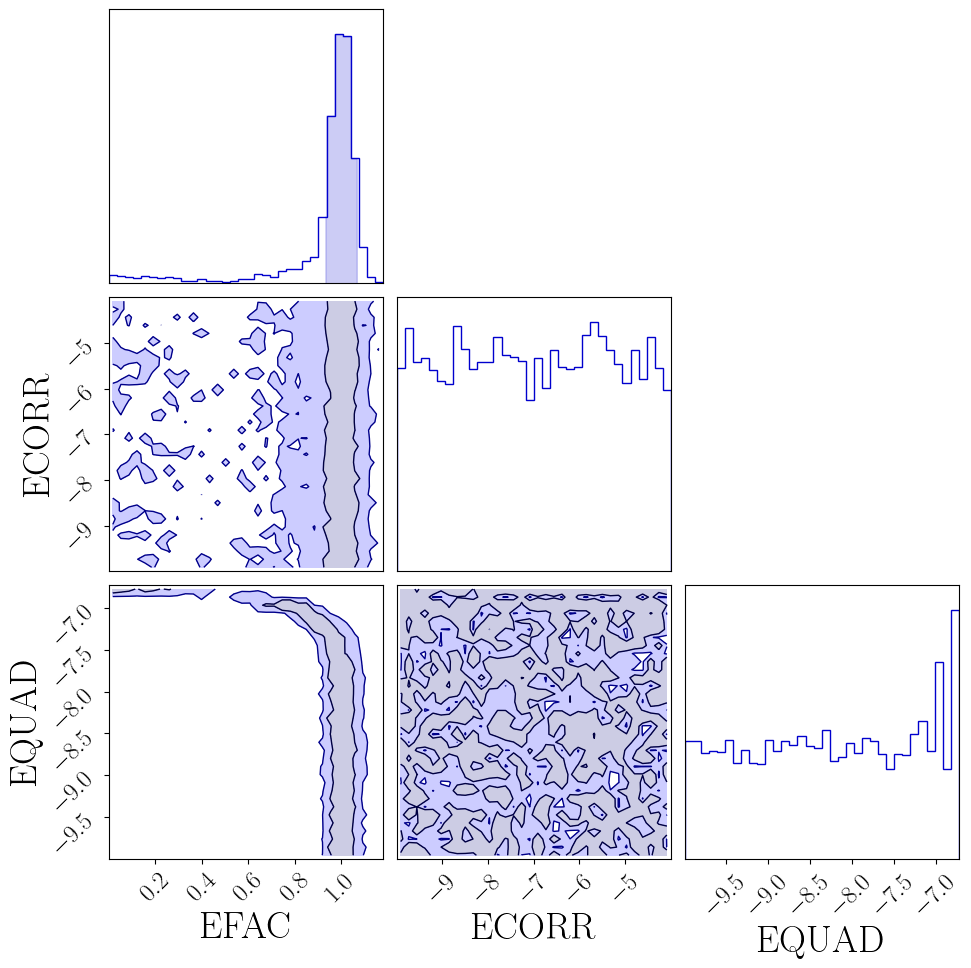

In [4]:
cpars = ['J1022+1001_mid_efac', 'J1022+1001_mid_log10_ecorr', 'J1022+1001_mid_log10_tnequad']
truth = [13./3.,-14.7]
all_indices = []
for cp in cpars:
    indices = [cp in p for p in pars]
    all_indices.append(indices)
indices = np.any(all_indices, axis=0)

corner_pars = pars[indices]
data = all_data[:, :-4]
data = data[:, indices]

cc = ChainConsumer()
parameters = ["EFAC", "ECORR", "EQUAD"]
cc.add_chain(data, parameters=parameters)
cc.configure(summary=False, linestyles=linestyles, linewidths=linewidths, sigmas=sigmas,
            shade=shade, bar_shade=shade, shade_alpha=shade_alpha, shade_gradient=shade_gradient, 
            legend_color_text=True, legend_artists=True, colors=colors, smooth=False,
            max_ticks=7, tick_font_size=tfs, label_font_size=lfs, spacing=1.0,
            legend_kwargs={'loc': 'lower right'})#, plot_hists=False)

cfig = cc.plotter.plot(truth=truth, figsize=(10, 10))
plt.show()

Now we plot the estimated parameters for the achromatic red nosie (timing noise). Injected values for pulsar J0437-4716: $$\gamma_{TN}=4.8$$ $$\log_{10}A_{TN}=-14.22$$

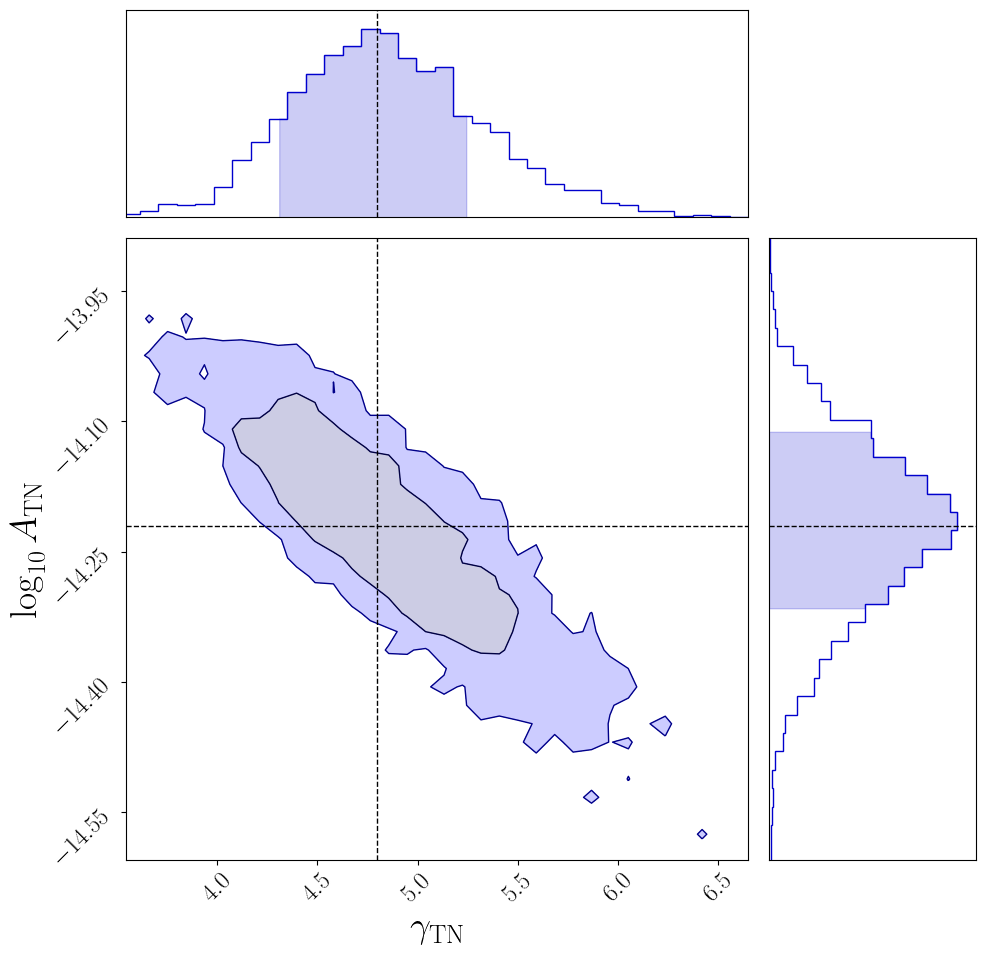

In [5]:
cpars = ['0437-4715_red_noise_gamma', '0437-4715_red_noise_log10_A']
truth = [4.8,-14.22]
all_indices = []
for cp in cpars:
    indices = [cp in p for p in pars]
    all_indices.append(indices)
indices = np.any(all_indices, axis=0)

corner_pars = pars[indices]
data = all_data[:, :-4]
data = data[:, indices]

cc = ChainConsumer()
parameters = [r"$\gamma_{\mathrm{TN}}$", r"$\log_{10}A_{\mathrm{TN}}$"]
cc.add_chain(data, parameters=parameters, name='Misspecified model')
cc.configure(summary=False, linestyles=linestyles, linewidths=linewidths, sigmas=sigmas,
            shade=shade, bar_shade=shade, shade_alpha=shade_alpha, shade_gradient=shade_gradient, 
            legend_color_text=True, legend_artists=True, colors=colors, smooth=False,
            max_ticks=7, tick_font_size=tfs, label_font_size=lfs, spacing=1.0, 
            legend_kwargs={'loc': 'lower right'})#, plot_hists=False)

cfig = cc.plotter.plot(truth=truth, figsize=(10, 10))
plt.show()

Now we plot the estimated parameters for the dispersion measure variations. Injected values for pulsar J0437-4716: $$\gamma_{DM}=3.3$$ $$\log_{10}A_{DM}=-14.3$$

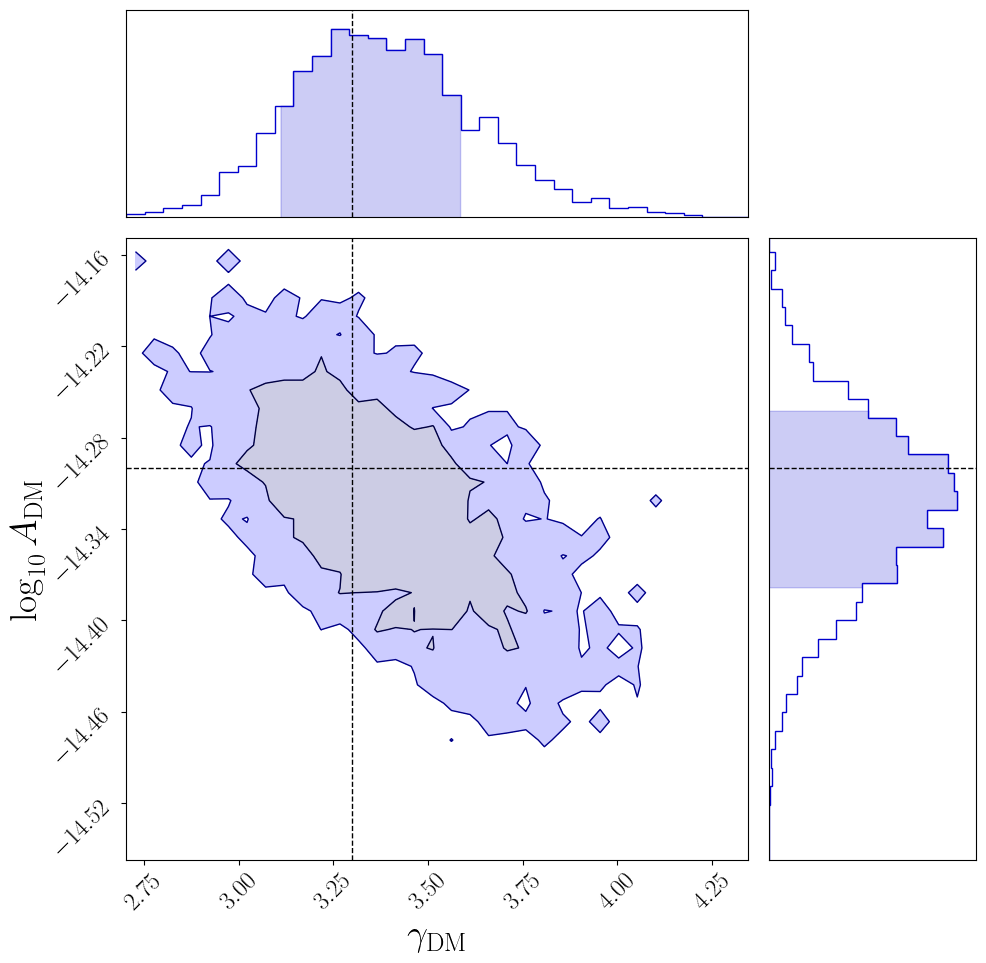

In [6]:
cpars = ['0437-4715_dm_gp_gamma', '0437-4715_dm_gp_log10_A']
truth = [3.3,-14.3]
all_indices = []
for cp in cpars:
    indices = [cp in p for p in pars]
    all_indices.append(indices)
indices = np.any(all_indices, axis=0)

corner_pars = pars[indices]
data = all_data[:, :-4]
data = data[:, indices]

cc = ChainConsumer()
parameters = [r"$\gamma_{\mathrm{DM}}$", r"$\log_{10}A_{\mathrm{DM}}$"]
cc.add_chain(data, parameters=parameters, name='Misspecified model')
cc.configure(summary=False, linestyles=linestyles, linewidths=linewidths, sigmas=sigmas,
            shade=shade, bar_shade=shade, shade_alpha=shade_alpha, shade_gradient=shade_gradient, 
            legend_color_text=True, legend_artists=True, colors=colors, smooth=False,
            max_ticks=7, tick_font_size=tfs, label_font_size=lfs, spacing=1.0, 
            legend_kwargs={'loc': 'lower right'})#, plot_hists=False)

cfig = cc.plotter.plot(truth=truth, figsize=(10, 10))
plt.show()

Finally we plot the estimated value for the common red noise parameters. Injected values: $$\gamma_{CRN}=13/3$$ $$\log_{10}A_{CRN}=-14.7$$

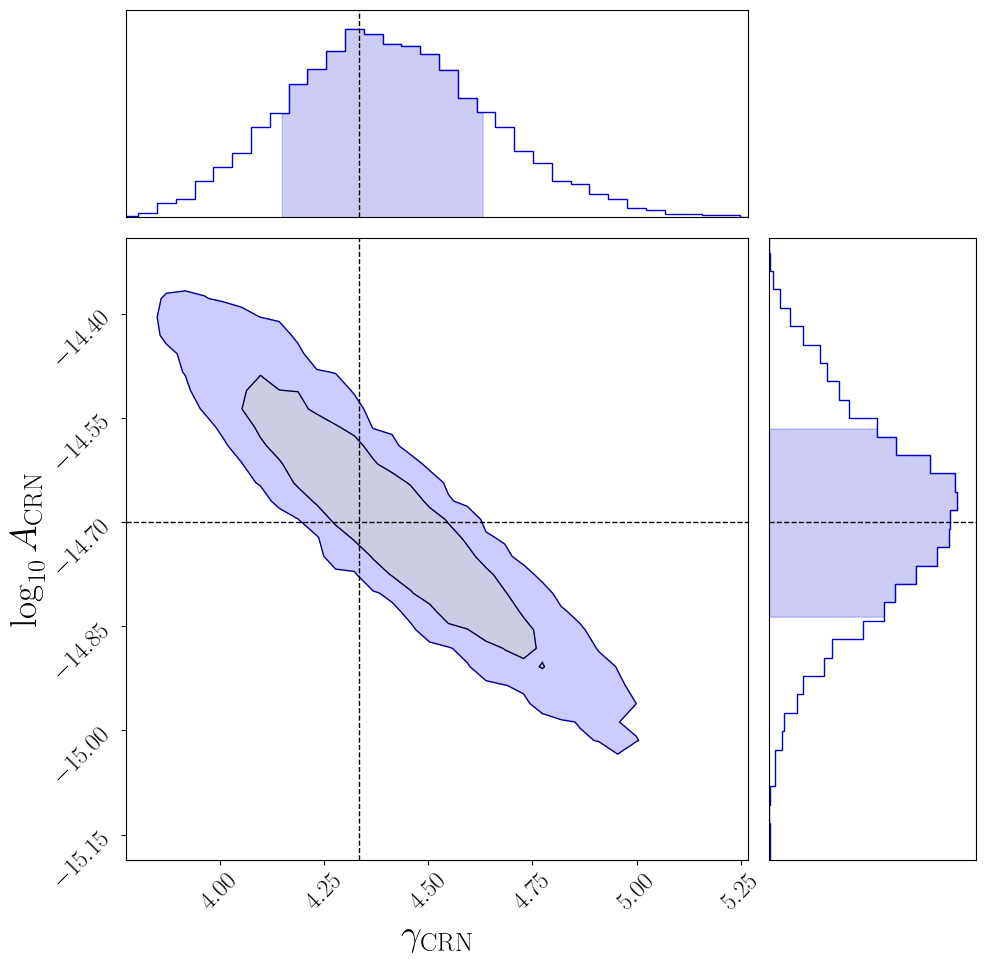

In [7]:
cpars = ['gw']
truth = [13./3.,-14.7]
all_indices = []
for cp in cpars:
    indices = [cp in p for p in pars]
    all_indices.append(indices)
indices = np.any(all_indices, axis=0)

corner_pars = pars[indices]
data = all_data[:, :-4]
data = data[:, indices]

cc = ChainConsumer()
parameters = [r"$\gamma_{\mathrm{CRN}}$", r"$\log_{10}A_{\mathrm{CRN}}$"]
cc.add_chain(data, parameters=parameters, name='Misspecified model')
cc.configure(summary=False, linestyles=linestyles, linewidths=linewidths, sigmas=sigmas,
            shade=shade, bar_shade=shade, shade_alpha=shade_alpha, shade_gradient=shade_gradient, 
            legend_color_text=True, legend_artists=True, colors=colors, smooth=False,
            max_ticks=7, tick_font_size=tfs, label_font_size=lfs, spacing=1.0, 
            legend_kwargs={'loc': 'lower right'})#, plot_hists=False)

cfig = cc.plotter.plot(truth=truth, figsize=(10, 10))
plt.show()

---

## The optimal statistic and the Hellings and Downs curve

The Optimal Statistic (OS) is a frequentist method derived by maximizing the PTA likelihood. It serves as an estimator of the amplitude of an isotropic stochastic gravitational wave background. By measuring the strength of cross-correlations between pulsar pairs, it helps identify the presence of a common signal. These measured correlations are then compared to the expected pattern given by the Hellings–Downs curve.

In [5]:
import os
import json
import matplotlib.pyplot as plt
import numpy as np
import glob
import csv
import pandas as pd
import time

from enterprise.signals import signal_base, selections
from enterprise.signals import gp_signals
from enterprise.pulsar import Pulsar
from enterprise_extensions import model_utils, blocks
from enterprise_extensions.frequentist import optimal_statistic as opt_stat

Load an existing array with some simulated data containing a strong gravitational wave signal

In [6]:
# Load up the noise dictionary to get values for the white noise parameters
dir_noise = '/fred/oz005/users/pulsar_workshop/valentina2/PTA_tutorials/chains_GW_huge/'
with open(dir_noise + '26Pulsars_chann_norn.json', 'r') as f:                          
    noisedict = json.load(f) 

# Load up the properly specified maximum-likelihood values for the pulsars' timing noise parameter                                                    
with open(dir_noise + 'huge_1.json', 'r') as f:                                                                        
    ml_params1 = json.load(f)


datadir = '/fred/oz005/users/pulsar_workshop/valentina2/PTA_tutorials/chains_GW_huge/real_1'
#set up pulsar objects 
parfiles = sorted(glob.glob(datadir + '/*par'))
timfiles = sorted(glob.glob(datadir + '/*tim'))

Setup the model, PTA object and the fixed white noise parameters from the dictionry

In [7]:
psrs = []
ephemeris = 'DE421'
for p, t in zip(parfiles, timfiles):
    psr = Pulsar(p, t, ephem=ephemeris)
    time.sleep(2)
    psrs.append(psr)
            
#set up model
Tspan = model_utils.get_tspan(psrs)
s = gp_signals.TimingModel()
by_band = selections.by_band
no_select = selections.no_selection
s += blocks.white_noise_block(vary=False, inc_ecorr=False, tnequad=True, select=no_select)
s += blocks.red_noise_block(prior='log-uniform', Tspan=Tspan, components=30)
s += blocks.common_red_noise_block(psd='powerlaw', prior='log-uniform', 
                                   Tspan=Tspan, components=5, gamma_val=4.33, name='gw')

# Set up the PTA object using the signal we defined above and the pulsars
pta = signal_base.PTA([s(p) for p in psrs])

# Set the white noise parameters to the values in the noise dictionary
pta.set_default_params(noisedict)

[tempo2Util.C:396] Warning: [TIM1] Please place MODE flags in the parameter file 
[tempo2Util.C:401] Warning: [DUP1] duplicated warnings have been suppressed.


INFO:enterprise.signals.signal_base:Setting J0437-4715_efac to 1.0
INFO:enterprise.signals.signal_base:Setting J0437-4715_log10_tnequad to -8.0
INFO:enterprise.signals.signal_base:Setting J0613-0200_efac to 1.0
INFO:enterprise.signals.signal_base:Setting J0613-0200_log10_tnequad to -8.0
INFO:enterprise.signals.signal_base:Setting J0711-6830_efac to 1.0
INFO:enterprise.signals.signal_base:Setting J0711-6830_log10_tnequad to -8.0
INFO:enterprise.signals.signal_base:Setting J1017-7156_efac to 1.0
INFO:enterprise.signals.signal_base:Setting J1017-7156_log10_tnequad to -8.0
INFO:enterprise.signals.signal_base:Setting J1022+1001_efac to 1.0
INFO:enterprise.signals.signal_base:Setting J1022+1001_log10_tnequad to -8.0
INFO:enterprise.signals.signal_base:Setting J1024-0719_efac to 1.0
INFO:enterprise.signals.signal_base:Setting J1024-0719_log10_tnequad to -8.0
INFO:enterprise.signals.signal_base:Setting J1045-4509_efac to 1.0
INFO:enterprise.signals.signal_base:Setting J1045-4509_log10_tnequad 

Run the Optimal statistics

In [4]:
ostat = opt_stat.OptimalStatistic(psrs, pta=pta, orf='hd')

# Compute the optimal statistic
# The optimal statistic returns five quantities:
#  - xi: an array of the angular separations between the pulsar pairs (in radians)
#  - rho: an array of the cross-correlations between the pulsar pairs
#  - sig: an array of the uncertainty in the cross-correlations
#  - OS: the value of the optimal statistic
#  - OS_sig: the uncertainty in the optimal statistic

xi, rho, sig, OS, OS_sig = ostat.compute_os(params=ml_params1)

#SNR_HD1 = OS/OS_sig

Some function definitions for the plots

In [5]:
# This function computes the weighted average and uncertainty
# for a set of values (rho) with associated uncertainties (sig).
# It returns the weighted average and the corresponding standard error.
def weightedavg(rho, sig):
    weights, avg = 0., 0.
    for r,s in zip(rho,sig):
        weights += 1./(s*s)
        avg += r/(s*s)
        
    return avg/weights, np.sqrt(1./weights)


# This function bins the cross-correlation data (rho) and associated uncertainties (sig)
# according to angular separation values (xi), using bins defined by zeta.
# Each bin spans 10 degrees in angle. It returns the binned weighted average
# cross-correlation and corresponding uncertainties.
def bin_crosscorr(zeta, xi, rho, sig):
    
    rho_avg, sig_avg = np.zeros(len(zeta)), np.zeros(len(zeta))
    
    for i,z in enumerate(zeta[:-1]):
        myrhos, mysigs = [], []
        for x,r,s in zip(xi,rho,sig):
            if x >= z and x < (z+10.):
                myrhos.append(r)
                mysigs.append(s)
        rho_avg[i], sig_avg[i] = weightedavg(myrhos, mysigs)
        
    return rho_avg, sig_avg

# This function outputs the Hellings and Downs curve for an array ov angles
def get_HD_curve(zeta):
    
    coszeta = np.cos(zeta*np.pi/180.)
    xip = (1.-coszeta) / 2.
    HD = 3.*( 1./3. + xip * ( np.log(xip) -1./6.) )
    
    return HD/2

Some sorting and binning for the plots

In [6]:
# sort the cross-correlations by xi
idx = np.argsort(xi)
xi_sorted = xi[idx]
rho_sorted = rho[idx]
sig_sorted = sig[idx]

# bin the cross-correlations so that there are the same number of pairs per bin
npairs = 20 # this is the number of pulsars we want in each bin

xi_mean = []
xi_err = []
rho_avg = []
sig_avg = []
i = 0
while i < len(xi_sorted):
    
    xi_mean.append(np.mean(xi_sorted[i:npairs+i]))
    xi_err.append(np.std(xi_sorted[i:npairs+i]))

    r, s = weightedavg(rho_sorted[i:npairs+i], sig_sorted[i:npairs+i])
    rho_avg.append(r)
    sig_avg.append(s)
    
    i += npairs
    
xi_mean = np.array(xi_mean)
xi_err = np.array(xi_err)

Plot!

/tmp/ipykernel_252152/1042844405.py:5: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.


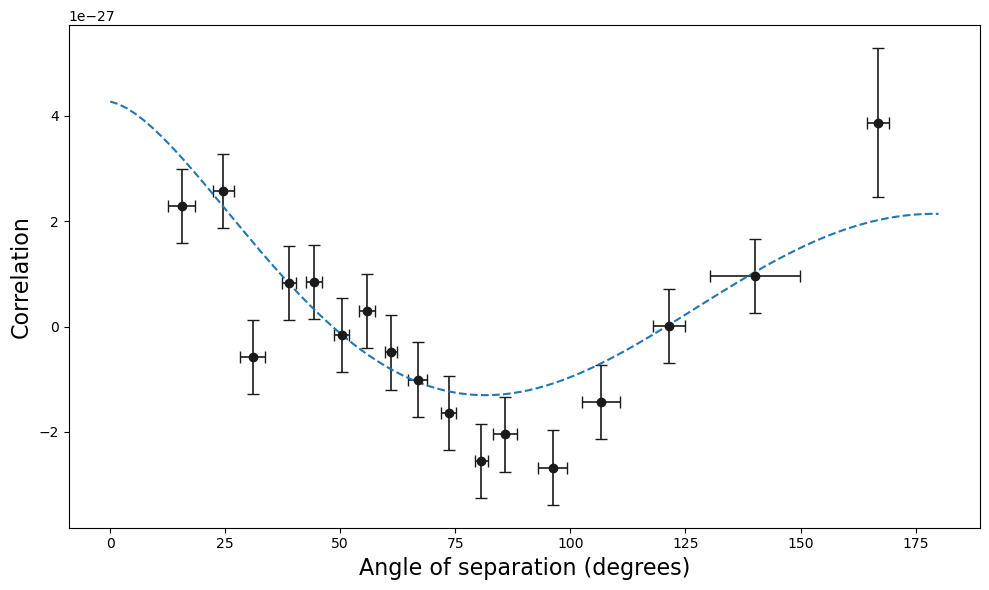

In [7]:
zeta = np.linspace(0.01,180,100)
HD = get_HD_curve(zeta+1)

plt.figure(figsize=(10, 6)) 
plt.errorbar(xi_mean*180/np.pi, rho_avg, xerr=xi_err*180/np.pi, yerr=sig_avg, marker='o', ls='', 
                            color='0.1', fmt='o', capsize=4, elinewidth=1.2)
plt.plot(zeta, OS*HD, ls='--', label='Hellings-Downs', color='C0', lw=1.5)
plt.xlabel('Angle of separation (degrees)', fontsize=16)
plt.ylabel('Correlation', fontsize=16)
plt.tight_layout()

You can find a very clear and comprehensive resource on pulsar timing here https://arxiv.org/abs/2105.13270